Mean Squared Error: 2.064638736569199e-05
Variance: 0.0008915320605357032


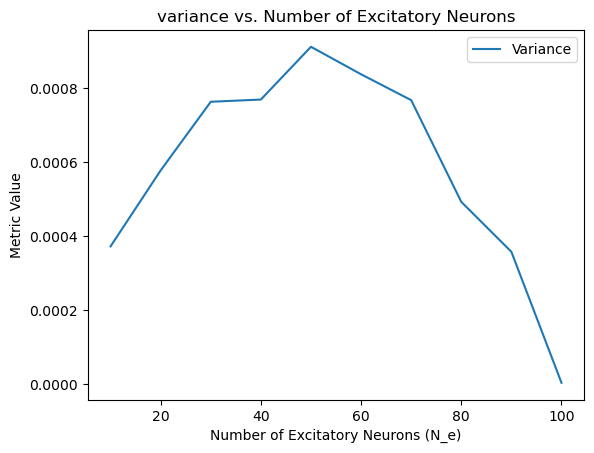

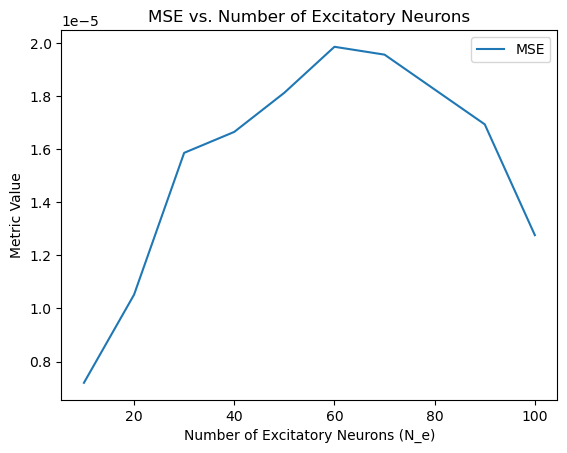

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_network(N_e, N_i, W_e, W_i, sigma_e, sigma_i, num_samples=1000):
    # Generate excitatory and inhibitory inputs
    X_e = np.random.uniform(0, 1, (N_e, num_samples))
    X_i = np.random.uniform(0, 1, (N_i, num_samples))
    
    # Calculate outputs without noise
    Y_clean = (W_e @ X_e) / (W_e @ X_e + W_i @ X_i + 1)
    
    # Add noise to the inputs
    noise_e = np.random.uniform(0, sigma_e, (N_e, num_samples))
    noise_i = np.random.uniform(0, sigma_i, (N_i, num_samples))
    X_e_noisy = X_e + noise_e
    X_i_noisy = X_i + noise_i
    
    # Calculate outputs with noise
    Y_noisy = (W_e @ X_e_noisy) / (W_e @ X_e_noisy + W_i @ X_i_noisy + 1)
    
    # Calculate performance metrics
    mse = np.mean((Y_clean - Y_noisy)**2)
    variance = np.var(Y_noisy)
    
    return mse, variance

def main():
    # Parameters
    N_e = 50
    N_i = 50
    W_e = np.random.uniform(0, 1, N_e)
    W_i = np.random.uniform(0, 1, N_i)
    sigma_e = 0.1
    sigma_i = 0.1
    
    # Simulate network
    mse, variance = simulate_network(N_e, N_i, W_e, W_i, sigma_e, sigma_i)
    
    print(f"Mean Squared Error: {mse}")
    print(f"Variance: {variance}")
    
    # Visualize
    N_e_values = range(10, 101, 10)
    mse_values = []
    var_values = []
    
    for N_e in N_e_values:
        N_i = 100 - N_e
        W_e = np.random.uniform(0, 1, N_e)
        W_i = np.random.uniform(0, 1, N_i)
        mse, var = simulate_network(N_e, N_i, W_e, W_i, sigma_e, sigma_i)
        mse_values.append(mse)
        var_values.append(var)
    
    plt.plot(N_e_values, var_values, label='Variance')
    plt.xlabel('Number of Excitatory Neurons (N_e)')
    plt.ylabel('Metric Value')
    plt.legend()
    plt.title('variance vs. Number of Excitatory Neurons')
    plt.show()
    
    plt.plot(N_e_values, mse_values, label='MSE')
    plt.xlabel('Number of Excitatory Neurons (N_e)')
    plt.ylabel('Metric Value')
    plt.legend()
    plt.title('MSE vs. Number of Excitatory Neurons')
    plt.show()

if __name__ == "__main__":
    main()

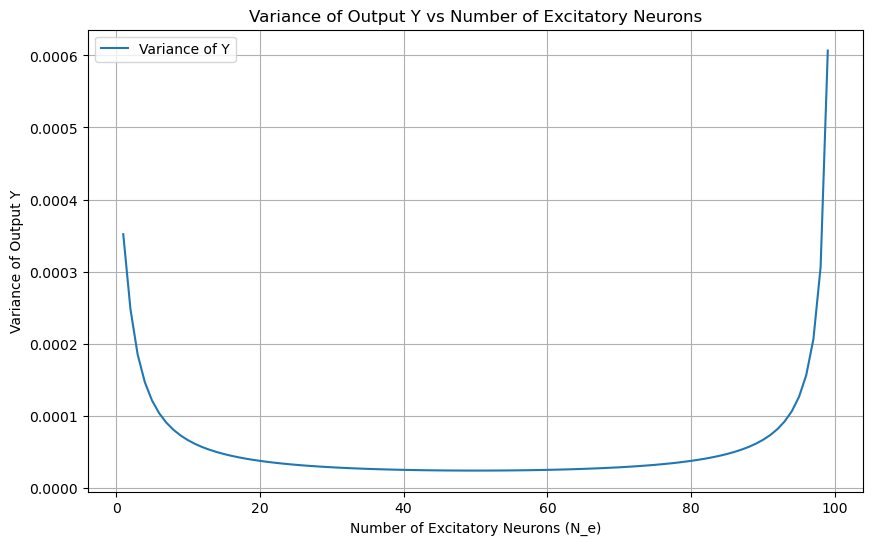

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_variance(N_e, N_i, W_e, W_i, sigma_e, sigma_i, I_e_mean=1, I_i_mean=1):
    """
    Calculate the variance of the output Y due to synaptic noise.
    
    Parameters:
    - N_e: Number of excitatory neurons
    - N_i: Number of inhibitory neurons
    - W_e: Weight associated with excitatory neurons
    - W_i: Weight associated with inhibitory neurons
    - sigma_e: Standard deviation of noise in excitatory inputs
    - sigma_i: Standard deviation of noise in inhibitory inputs
    - I_e_mean: Mean of excitatory input
    - I_i_mean: Mean of inhibitory input
    
    Returns:
    - variance_Y: Variance of the output Y
    """
    # Calculate the variances of excitatory and inhibitory inputs
    var_W_e_I_e = W_e**2 * sigma_e**2 * N_e
    var_W_i_I_i = W_i**2 * sigma_i**2 * N_i

    # Mean values of W_e * I_e and W_i * I_i
    E_W_e_I_e = W_e * I_e_mean * N_e
    E_W_i_I_i = W_i * I_i_mean * N_i
    ro = 1 #N_e / N_i

    # Calculate the variance of the output Y
    numerator = var_W_e_I_e * (ro * E_W_i_I_i + 1)**2 + var_W_i_I_i * (ro * E_W_e_I_e)**2
    denominator = (E_W_e_I_e + ro * E_W_i_I_i + 1)**4
    variance_Y = numerator / denominator

    return variance_Y

# Parameters
W_e = 0.5
W_i = 0.5
sigma_e = 0.1
sigma_i = 0.1
total_neurons = 100

# Arrays to store results
N_e_values = np.arange(1, total_neurons )
variances = []

# Calculate variance for each combination of N_e and N_i
for N_e in N_e_values:
    N_i = total_neurons - N_e
    variance_Y = calculate_variance(N_e, N_i, W_e, W_i, sigma_e, sigma_i)
    variances.append(variance_Y)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(N_e_values, variances, label='Variance of Y')
plt.xlabel('Number of Excitatory Neurons (N_e)')
plt.ylabel('Variance of Output Y')
plt.title('Variance of Output Y vs Number of Excitatory Neurons')
plt.legend()
plt.grid(True)
plt.show()

/n/home13/hsafaai/.conda/envs/hsafaai_env/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/n/home13/hsafaai/.conda/envs/hsafaai_env/lib/python3.10/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


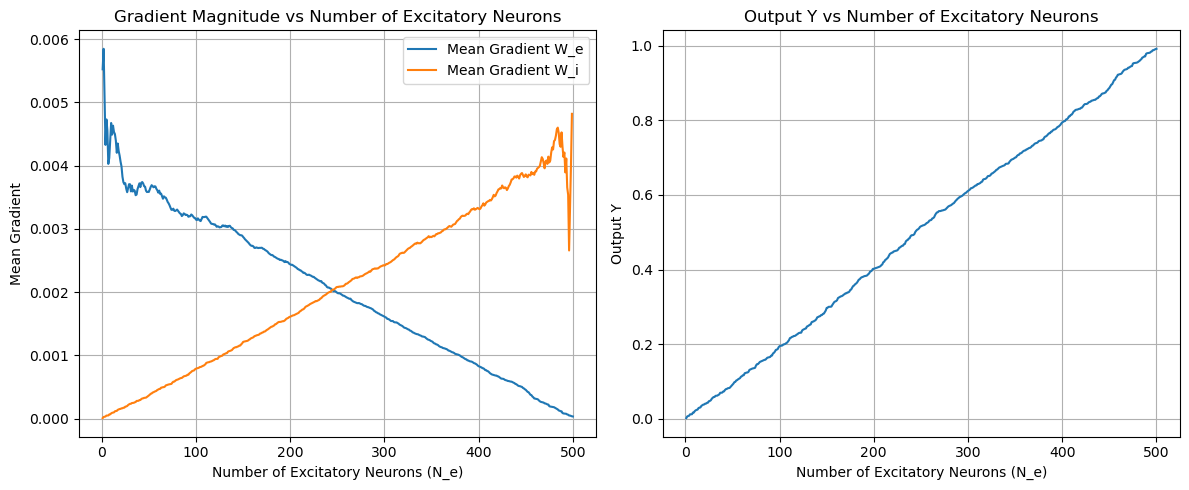

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def shunting_activation_gradient(N_e, N_i, W_e, W_i, I_e, I_i):
    """
    Compute gradients of the shunting activation function with respect to W_e and W_i.
    
    Parameters:
    - N_e: Number of excitatory neurons
    - N_i: Number of inhibitory neurons
    - W_e: Excitatory synaptic weights (array of length N_e)
    - W_i: Inhibitory synaptic weights (array of length N_i)
    - I_e: Excitatory inputs (array of length N_e)
    - I_i: Inhibitory inputs (array of length N_i)
    
    Returns:
    - grad_W_e: Gradient with respect to excitatory weights (array of length N_e)
    - grad_W_i: Gradient with respect to inhibitory weights (array of length N_i)
    """
    # Compute total input contributions
    excitatory_input = np.dot(W_e, I_e)
    inhibitory_input = np.dot(W_i, I_i)
    
    # Compute output Y
    Y = excitatory_input / (excitatory_input + inhibitory_input + 1)
    
    # Compute gradients
    grad_W_e = (inhibitory_input + 1) * I_e / (excitatory_input + inhibitory_input + 1)**2
    grad_W_i = -excitatory_input * I_i / (excitatory_input + inhibitory_input + 1)**2
    
    return grad_W_e, grad_W_i, Y

# Parameters
N_e_values = np.arange(1, 501)
N_i = 500 - N_e_values
W_e = np.random.uniform(0, 1, 500)  # Random weights for simulation
W_i = np.random.uniform(0, 1, 500)
I_e = np.random.uniform(0, 1, 500)  # Random inputs for simulation
I_i = np.random.uniform(0, 1, 500)

# Arrays to store results
mean_grad_W_e = []
mean_grad_W_i = []
output_Y = []

# Simulation
for N_e in N_e_values:
    grad_W_e, grad_W_i, Y = shunting_activation_gradient(
        N_e=N_e, 
        N_i=500 - N_e, 
        W_e=W_e[:N_e], 
        W_i=W_i[:500-N_e], 
        I_e=I_e[:N_e], 
        I_i=I_i[:500-N_e]
    )
    mean_grad_W_e.append(np.mean(np.abs(grad_W_e)))
    mean_grad_W_i.append(np.mean(np.abs(grad_W_i)))
    output_Y.append(Y)

# Plotting
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(N_e_values, mean_grad_W_e, label='Mean Gradient W_e')
plt.plot(N_e_values, mean_grad_W_i, label='Mean Gradient W_i')
plt.xlabel('Number of Excitatory Neurons (N_e)')
plt.ylabel('Mean Gradient')
plt.title('Gradient Magnitude vs Number of Excitatory Neurons')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(N_e_values, output_Y)
plt.xlabel('Number of Excitatory Neurons (N_e)')
plt.ylabel('Output Y')
plt.title('Output Y vs Number of Excitatory Neurons')
plt.grid(True)

plt.tight_layout()
plt.show()

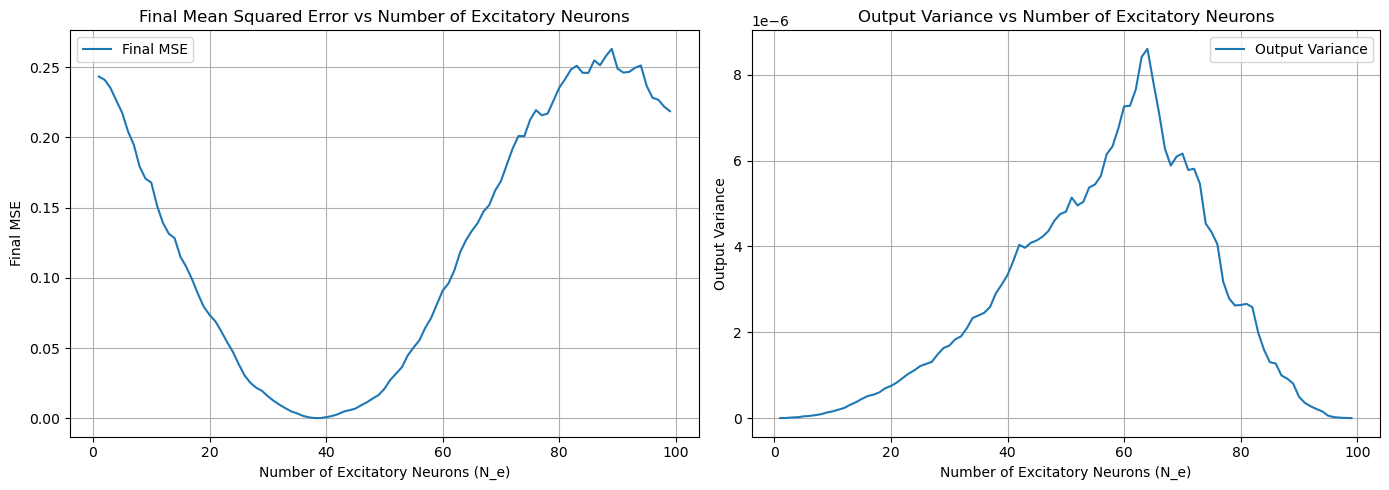

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def shunting_activation_gradient_complex(N_e, N_i, W_e, W_i, I_e, I_i, activation_func='shunting'):
    """
    Compute gradients of a more complex activation function with respect to W_e and W_i.
    
    Parameters:
    - N_e: Number of excitatory neurons
    - N_i: Number of inhibitory neurons
    - W_e: Excitatory synaptic weights (array of length N_e)
    - W_i: Inhibitory synaptic weights (array of length N_i)
    - I_e: Excitatory inputs (array of length N_e)
    - I_i: Inhibitory inputs (array of length N_i)
    - activation_func: Activation function type ('shunting', 'relu', 'sigmoid', 'sigmoid_shunting')
    
    Returns:
    - grad_W_e: Gradient with respect to excitatory weights (array of length N_e)
    - grad_W_i: Gradient with respect to inhibitory weights (array of length N_i)
    - Y: Output of the neuron
    """
    # Compute total input contributions
    excitatory_input = np.dot(W_e, I_e)
    inhibitory_input = np.dot(W_i, I_i)
    
    if activation_func == 'shunting':
        # Shunting activation function
        Y = excitatory_input / (excitatory_input + inhibitory_input + 1)
    elif activation_func == 'relu':
        # ReLU activation function
        Y = np.maximum(0, excitatory_input - inhibitory_input)
    elif activation_func == 'sigmoid':
        # Sigmoid activation function
        Y = 1 / (1 + np.exp(-(excitatory_input - inhibitory_input)))
    elif activation_func == 'sigmoid_shunting':
        # Sigmoid of Shunting activation function
        shunting_output = excitatory_input / (excitatory_input + inhibitory_input + 1)
        Y = 1 / (1 + np.exp(-shunting_output))
    else:
        raise ValueError("Unsupported activation function")
    
    # Compute gradients based on activation function
    if activation_func == 'shunting':
        grad_W_e = (inhibitory_input + 1) * I_e / (excitatory_input + inhibitory_input + 1)**2
        grad_W_i = -excitatory_input * I_i / (excitatory_input + inhibitory_input + 1)**2
    elif activation_func == 'relu':
        grad_W_e = (Y > 0) * I_e
        grad_W_i = -(Y > 0).astype(float) * I_i  # Fixed: convert to float for multiplication
    elif activation_func == 'sigmoid':
        sig = 1 / (1 + np.exp(-(excitatory_input - inhibitory_input)))
        grad_W_e = sig * (1 - sig) * I_e
        grad_W_i = -sig * (1 - sig) * I_i
    elif activation_func == 'sigmoid_shunting':
        sig = 1 / (1 + np.exp(-shunting_output))
        grad_shunting = (inhibitory_input + 1) / (excitatory_input + inhibitory_input + 1)**2
        grad_W_e = sig * (1 - sig) * grad_shunting * I_e
        grad_W_i = -sig * (1 - sig) * grad_shunting * I_i
    
    return grad_W_e, grad_W_i, Y

def train_network_complex(N_e, N_i, W_e, W_i, I_e, I_i, target_Y, learning_rate=0.001, epochs=100, activation_func='shunting'):
    """
    Simulate training of a more complex network and return performance metrics.
    
    Parameters:
    - N_e: Number of excitatory neurons
    - N_i: Number of inhibitory neurons
    - W_e: Excitatory synaptic weights (array of length N_e)
    - W_i: Inhibitory synaptic weights (array of length N_i)
    - I_e: Excitatory inputs (array of length N_e)
    - I_i: Inhibitory inputs (array of length N_i)
    - target_Y: Desired output
    - learning_rate: Learning rate for weight updates
    - epochs: Number of training epochs
    - activation_func: Activation function type
    
    Returns:
    - mse_list: List of MSE values over epochs
    - final_variance: Variance of the output after training
    """
    mse_list = []
    outputs = []

    for epoch in range(epochs):
        grad_W_e, grad_W_i, Y = shunting_activation_gradient_complex(N_e, N_i, W_e, W_i, I_e, I_i, activation_func)
        
        # Update weights with added complexity (regularization term)
        W_e += learning_rate * (grad_W_e - 0.01 * W_e)  # L2 Regularization
        W_i += learning_rate * (grad_W_i - 0.01 * W_i)  # L2 Regularization
        
        # Compute MSE
        mse = np.mean((Y - target_Y) ** 2)
        mse_list.append(mse)
        outputs.append(Y)
        
    # Compute variance of the output
    final_variance = np.var(outputs)
    
    return mse_list, final_variance

# Simulation parameters
N_total = 100  # Total number of neurons
W_e = np.random.uniform(0, 1, N_total)  # Random weights for simulation
W_i = np.random.uniform(0, 1, N_total)
I_e = np.random.normal(0.5, 0.1, N_total)  # Gaussian inputs for simulation
I_i = np.random.normal(0.5, 0.1, N_total)
target_Y = 0.5  # Desired target output
learning_rate = 0.001
epochs = 500

# Arrays to store results
N_e_values = np.arange(1, N_total)
mse_results = []
variance_results = []

# Simulation
for N_e in N_e_values:
    N_i = N_total - N_e
    mse_list, final_variance = train_network_complex(
        N_e=N_e,
        N_i=N_i,
        W_e=W_e[:N_e],
        W_i=W_i[:N_i],
        I_e=I_e[:N_e],
        I_i=I_i[:N_i],
        target_Y=target_Y,
        learning_rate=learning_rate,
        epochs=epochs,
        activation_func='shunting'#'sigmoid_shunting'  # Choose activation function here
    )
    mse_results.append(mse_list[-1])  # Store the final MSE
    variance_results.append(final_variance)

# Plotting
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(N_e_values, mse_results, label='Final MSE')
plt.xlabel('Number of Excitatory Neurons (N_e)')
plt.ylabel('Final MSE')
plt.title('Final Mean Squared Error vs Number of Excitatory Neurons')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(N_e_values, variance_results, label='Output Variance')
plt.xlabel('Number of Excitatory Neurons (N_e)')
plt.ylabel('Output Variance')
plt.title('Output Variance vs Number of Excitatory Neurons')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Epoch [10/10], Loss: 1.4815
Epoch [10/10], Loss: 21.0308
Epoch [10/10], Loss: 1.4185
Epoch [10/10], Loss: 0.5978
Epoch [10/10], Loss: 0.0329
Epoch [10/10], Loss: 0.1111
Epoch [10/10], Loss: 0.3055
Epoch [10/10], Loss: 0.0024
Epoch [10/10], Loss: 16.4639
Epoch [10/10], Loss: 0.4268
Epoch [10/10], Loss: 0.0281
Epoch [10/10], Loss: 0.1388
Epoch [10/10], Loss: 1.7206
Epoch [10/10], Loss: 0.0132
Epoch [10/10], Loss: 0.1313
Epoch [10/10], Loss: 0.0540
Epoch [10/10], Loss: 0.0042
Epoch [10/10], Loss: 0.0031
Epoch [10/10], Loss: 0.0518
Epoch [10/10], Loss: 0.0248
Epoch [10/10], Loss: 4.9491
Epoch [10/10], Loss: 16.0769
Epoch [10/10], Loss: 0.0377
Epoch [10/10], Loss: 0.6079
Epoch [10/10], Loss: 3.1934
Epoch [10/10], Loss: 0.3443
Epoch [10/10], Loss: 0.0967
Epoch [10/10], Loss: 0.4474
Epoch [10/10], Loss: 0.4524
Epoch [10/10], Loss: 35.5406
Epoch [10/10], Loss: 66.3498
Epoch [10/10], Loss: 117.5702
Epoch [10/10], Loss: 0.1033
Epoch [10/10], Loss: 0.0024
Epoch [10/10], Loss: 0.0574
Epoch [10/10]

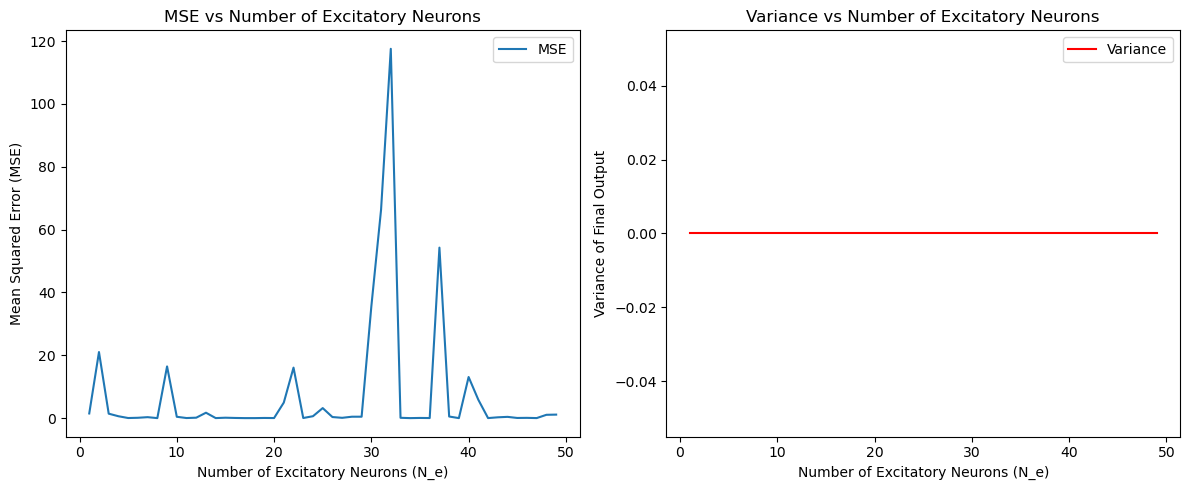

In [30]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Define network architecture with batch normalization and optional dropout
class SimpleNetwork(nn.Module):
    def __init__(self, N_e, N_i, dropout_prob=0.5, use_dropout=True):
        super(SimpleNetwork, self).__init__()
        self.N_e = N_e
        self.N_i = N_i
        self.use_dropout = use_dropout  # Add flag for using dropout
        if self.use_dropout:
            self.dropout = nn.Dropout(dropout_prob)
        self.batch_norm_e = nn.BatchNorm1d(N_e)
        self.batch_norm_i = nn.BatchNorm1d(N_i)
        # Initialize weights
        self.W_e = nn.Parameter(torch.randn(N_e))
        self.W_i = nn.Parameter(torch.randn(N_i))

    def forward(self, I_e, I_i, activation_func='shunting'):
        # Ensure inputs are 2D for batch normalization
        I_e = I_e.unsqueeze(0)  # Add batch dimension
        I_i = I_i.unsqueeze(0)

        # Apply batch normalization only if batch size > 1
        if I_e.size(0) > 1:
            I_e = self.batch_norm_e(I_e)
            I_i = self.batch_norm_i(I_i)

        # Remove batch dimension after normalization
        I_e = I_e.squeeze(0)
        I_i = I_i.squeeze(0)

        # Compute inputs
        excitatory_input = torch.sum(self.W_e * I_e)
        inhibitory_input = torch.sum(self.W_i * I_i)

        if activation_func == 'shunting':
            Y = excitatory_input / (excitatory_input + inhibitory_input + 1)
        elif activation_func == 'relu':
            Y = torch.relu(excitatory_input - inhibitory_input)
        elif activation_func == 'sigmoid':
            Y = torch.sigmoid(excitatory_input - inhibitory_input)
        else:
            raise ValueError("Unknown activation function")

        # Apply dropout during training if enabled
        if self.use_dropout:
            Y = self.dropout(Y)
        return Y

# Define training function with L2 regularization
def train_network_with_regularization(N_e, N_i, W_e, W_i, I_e, I_i, target_Y, learning_rate=0.01, epochs=100, activation_func='shunting', lambda_l2=0.0, use_dropout=True):
    # Convert input arrays to tensors
    W_e, W_i, I_e, I_i, target_Y = map(torch.tensor, (W_e, W_i, I_e, I_i, target_Y))
    W_e, W_i = W_e.float(), W_i.float()
    I_e, I_i, target_Y = I_e.float(), I_i.float(), target_Y.float()
    
    # Initialize the network with optional dropout
    net = SimpleNetwork(N_e, N_i, dropout_prob=0.5, use_dropout=use_dropout)
    
    # Define optimizer with L2 regularization (weight decay)
    optimizer = optim.Adam(net.parameters(), lr=learning_rate, weight_decay=lambda_l2)
    
    # Define loss function
    criterion = nn.MSELoss()

    mse_list = []
    
    # Training loop
    for epoch in range(epochs):
        net.train()
        optimizer.zero_grad()

        # Forward pass
        output = net(I_e, I_i, activation_func)
        
        # Compute loss
        loss = criterion(output, target_Y)
        mse_list.append(loss.item())
        
        # Backward pass and optimize
        loss.backward()
        optimizer.step()
        
        if (epoch+1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

    # Calculate final output variance
    net.eval()
    with torch.no_grad():
        outputs = []
        for _ in range(100):  # Sample multiple times to estimate variance
            outputs.append(net(I_e, I_i, activation_func).item())
        final_variance = np.var(outputs)

    return net, mse_list, final_variance

# Function to run the experiment for different values of N_e and plot MSE and variance
def run_experiment(N_total, W_e, W_i, I_e, I_i, target_Y, learning_rate=0.01, epochs=100, activation_func='shunting', lambda_l2=0.0, use_dropout=True):
    mse_results = []
    variance_results = []
    N_e_values = range(1, N_total)  # Vary N_e from 1 to N_total-1
    for N_e in N_e_values:
        N_i = N_total - N_e
        _, mse_list, final_variance = train_network_with_regularization(
            N_e=N_e,
            N_i=N_i,
            W_e=W_e[:N_e],
            W_i=W_i[:N_i],
            I_e=I_e[:N_e],
            I_i=I_i[:N_i],
            target_Y=target_Y,
            learning_rate=learning_rate,
            epochs=epochs,
            activation_func=activation_func,
            lambda_l2=lambda_l2,
            use_dropout=use_dropout
        )
        mse_results.append(mse_list[-1])  # Store the final MSE
        variance_results.append(final_variance)  # Store the final variance

    # Plot MSE results
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(N_e_values, mse_results, label='MSE')
    plt.xlabel('Number of Excitatory Neurons (N_e)')
    plt.ylabel('Mean Squared Error (MSE)')
    plt.title('MSE vs Number of Excitatory Neurons')
    plt.legend()

    # Plot Variance results
    plt.subplot(1, 2, 2)
    plt.plot(N_e_values, variance_results, label='Variance', color='red')
    plt.xlabel('Number of Excitatory Neurons (N_e)')
    plt.ylabel('Variance of Final Output')
    plt.title('Variance vs Number of Excitatory Neurons')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Example Usage
N_total = 50
W_e = np.random.uniform(0, 1, N_total)
W_i = np.random.uniform(0, 1, N_total)
I_e = np.random.uniform(0, 1, N_total)
I_i = np.random.uniform(0, 1, N_total)
target_Y = np.array([0.5])  # Example target

run_experiment(N_total, W_e, W_i, I_e, I_i, target_Y, learning_rate=0.00001, epochs=10, activation_func='shunting', use_dropout=False)  # Use dropout=False to disable dropout